# ASL Identifiability-Aware Architecture

**Standalone synthetic research notebook.** This notebook compares the reference four-PLD spatial U-Net with an experimental timing-conditioned model for estimating cerebral blood flow (CBF, ml/100 g/min) and arterial transit time (ATT, seconds). It tests an identifiability hypothesis; it does not presume that the proposed model is better or novel.

Run from the `CNN-UNET` project folder in VS Code. The default **smoke** settings make a short CPU/GPU-capable run; edit the single configuration cell to request the much more expensive reference-scale experiment. Synthetic results do not establish clinical performance or simulation-to-real transfer.

## 1. Objective, hypothesis, and configuration

Multi-PLD ASL observes a signal at several post-labeling delays. CBF controls perfusion amplitude and ATT controls arrival timing. These parameters can be difficult to distinguish when the measurements are noisy or their local signal derivatives are similar. The hypothesis is that an explicit local information/reliability signal may help spatial estimation, especially for ATT. The hypothesis will be measured, not presumed.

The reference constants below are read from the public repository's `data_gen.py` and `experiments_unet_4pld/config.json`. Its established observation convention is a sum of two independent Rician magnitudes, not control-minus-label subtraction. Do not interpret it as a conventional physical difference signal.

In [1]:
import json, math, os, platform, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import ndimage, stats
from scipy.special import i0e, i1e
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

CONFIG = {
    "mode": "smoke",  # "smoke", "optimized", or "full"
    "image_size": 64,
    "plds_s": [1.525, 2.025, 2.525, 3.025],
    "tau_s": 1.8, "T1t_s": 1.2, "T1a_s": 1.66,
    "alpha": 0.85, "beta": 0.75, "lambda": 0.9,
    "signal_scale": 100000.0, "signal_reference": 334.2039,
    "sigma_max": 66.84078,
    "cbf_bounds": [0.0, 100.0], "att_bounds_s": [0.5, 3.0],
    "seeds": [42, 123, 2024],
    "train_seed": 42, "val_seed": 99, "test_seed": 7,
    "smoke": {
        "n_train": 12, "n_val": 4, "n_test": 6,
        "features": [8, 16, 32, 64], "epochs": 2,
        "batch_size": 2, "patience": 2, "stress_n": 3,
    },
    "optimized": {
        "n_train": 240, "n_val": 48, "n_test": 30,
        "features": [16, 32, 64, 128], "epochs": 35,
        "batch_size": 4, "patience": 8, "stress_n": 12,
    },
    "full": {
        "n_train": 600, "n_val": 100, "n_test": 100,
        "features": [32, 64, 128, 256], "epochs": 80,
        "batch_size": 2, "patience": 12, "stress_n": 30,
    },
    "learning_rate": 1e-3, "weight_decay": 1e-4,
    "lr_factor": 0.5, "lr_patience": 5, "min_lr": 1e-6,
    "physics_weight": 0.0,  # signal-domain residual is approximate, not a Rician likelihood
    "optimized_supervised_loss": "mse",
    "optimized_cbf_loss_weight": 4.0,
    "run_ablation": False, "run_three_seeds": False,
    "resume": False, "output_dir": "outputs/ia_aslnet_experiment",
    "train_snr_choices": [10.0, 15.0, 20.0],
    "test_snr_choices": [10.0, 15.0],
}
if CONFIG["mode"] not in {"smoke", "optimized", "full"}:
    raise ValueError("CONFIG['mode'] must be 'smoke', 'optimized', or 'full'.")
ACTIVE = CONFIG[CONFIG["mode"]]
ROOT = Path.cwd()
OUT = ROOT / CONFIG["output_dir"]
OUT.mkdir(parents=True, exist_ok=True)
print("Configuration mode:", CONFIG["mode"])
print("Project root:", ROOT.resolve())
print("Output folder:", OUT.resolve())

Configuration mode: smoke
Project root: D:\ASL PARAMETER\CNN-UNET\notebooks
Output folder: D:\ASL PARAMETER\CNN-UNET\notebooks\outputs\ia_aslnet_experiment


## 2. Device and environment checks

The notebook detects CUDA and available memory at runtime. CPU execution remains valid for the smoke test. If CUDA is unavailable, training runs on CPU and the notebook says so explicitly; full-scale settings may then be slow.

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
gpu_mem_gib = (
    torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    if torch.cuda.is_available() else None
)
print({
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": gpu_name,
    "gpu_memory_GiB": gpu_mem_gib,
    "selected_device": str(DEVICE),
})
if not torch.cuda.is_available():
    warnings.warn("CUDA is not active; using CPU. No GPU execution is claimed.")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Determinism is preferred for this experiment; unsupported deterministic
    # kernels raise explicitly instead of silently changing behavior.
    torch.use_deterministic_algorithms(True, warn_only=True)

set_seed(CONFIG["seeds"][0])
_device_probe = torch.randn(2, 4, 64, 64, device=DEVICE)
assert torch.isfinite(_device_probe).all()
print("Small device tensor test passed on", DEVICE)
print("Dependency install (only if needed): python -m pip install -r requirements.txt")

{'python': '3.10.11', 'pytorch': '2.5.1+cu121', 'numpy': '2.2.6', 'scipy': '1.15.3', 'cuda_available': True, 'gpu': 'NVIDIA GeForce GTX 1650', 'gpu_memory_GiB': 3.99969482421875, 'selected_device': 'cuda'}
Small device tensor test passed on cuda
Dependency install (only if needed): python -m pip install -r requirements.txt


## 3. Audited ASL forward model

The reference single-voxel signal is

`f = CBF / (6000 lambda)`,
`S = 2 alpha beta T1t (1/lambda) f exp(-ATT/T1a) [exp(-max(PLD-ATT,0)/T1t) - exp(-max(tau+PLD-ATT,0)/T1t)]`.

The repository multiplies this signal by `SCALE=100000`. It then draws four independent Gaussian noise terms per PLD and forms `Mc=sqrt((sig+e1)^2+e2^2)`, `Ml=sqrt((sig+e3)^2+e4^2)`, `X=Mc+Ml`. With zero noise, `X=2*sig`. At nonzero noise, the exact mean is twice the Rician mean, not exactly `2*sig`; `2*sig` is the high-SNR approximation. The two magnitudes have independent noise, so at high SNR the approximate variance of their sum is `2 sigma^2`.

In [3]:
PLDS = np.asarray(CONFIG["plds_s"], dtype=np.float64)
TAU, T1T, T1A = CONFIG["tau_s"], CONFIG["T1t_s"], CONFIG["T1a_s"]
ALPHA, BETA, LAMBDA = CONFIG["alpha"], CONFIG["beta"], CONFIG["lambda"]
SCALE = CONFIG["signal_scale"]

def asl_signal_numpy(cbf, att, plds=PLDS, scale=SCALE):
    cbf = np.asarray(cbf, dtype=np.float64)
    att = np.asarray(att, dtype=np.float64)
    plds = np.asarray(plds, dtype=np.float64)
    cbf, att = np.broadcast_arrays(cbf, att)
    f_per_s = cbf[..., None] / (6000.0 * LAMBDA)
    delta = att[..., None]
    pld = plds.reshape((1,) * cbf.ndim + (-1,))
    prefix = 2.0 * ALPHA * BETA * T1T * (1.0 / LAMBDA) * f_per_s
    e_att = np.exp(-delta / T1A)
    t1 = np.exp(-np.maximum(pld - delta, 0.0) / T1T)
    t2 = np.exp(-np.maximum(TAU + pld - delta, 0.0) / T1T)
    return (prefix * e_att * (t1 - t2) * scale).astype(np.float64)

def asl_signal_torch(cbf, att, plds, scale=SCALE):
    # cbf, att: [B,H,W] or broadcast-compatible; plds: [B,L] or [L]
    if plds.ndim == 1:
        plds = plds[None, :]
    f_per_s = cbf / (6000.0 * LAMBDA)
    delta = att
    pld = plds[:, :, None, None]
    prefix = 2.0 * ALPHA * BETA * T1T * (1.0 / LAMBDA) * f_per_s[:, None]
    e_att = torch.exp(-delta[:, None] / T1A)
    t1 = torch.exp(-torch.clamp(pld - delta[:, None], min=0.0) / T1T)
    t2 = torch.exp(-torch.clamp(TAU + pld - delta[:, None], min=0.0) / T1T)
    return prefix * e_att * (t1 - t2) * scale

def noisy_sum_of_ricians(signal, sigma, rng):
    signal = np.asarray(signal, dtype=np.float64)
    e = [rng.normal(0.0, sigma, size=signal.shape) for _ in range(4)]
    mc = np.sqrt((signal + e[0]) ** 2 + e[1] ** 2)
    ml = np.sqrt((signal + e[2]) ** 2 + e[3] ** 2)
    return (mc + ml).astype(np.float32)

## 4. Forward-model and noise verification

These tests exercise boundary parameter values, PLDs, finite values, NumPy/PyTorch agreement, the zero-noise factor of two, and the exact Rician-variance reference for a fixed signal amplitude. At high SNR, the latter approaches `2 sigma^2`.

In [4]:
def run_forward_tests():
    cbf_grid = np.array([0.0, 20.0, 55.0, 100.0])
    att_grid = np.array([0.5, 1.25, 2.2, 3.0])
    test_plds = np.array([0.7, 1.525, 2.525, 4.0])
    nps = asl_signal_numpy(cbf_grid, att_grid, test_plds)
    tcbf = torch.tensor(cbf_grid, dtype=torch.float64, device=DEVICE)[:, None, None]
    tatt = torch.tensor(att_grid, dtype=torch.float64, device=DEVICE)[:, None, None]
    tpls = torch.tensor(test_plds, dtype=torch.float64, device=DEVICE)
    tps = asl_signal_torch(tcbf, tatt, tpls).squeeze(-1).squeeze(-1).cpu().numpy()
    assert nps.shape == (4, 4) and np.isfinite(nps).all()
    np.testing.assert_allclose(nps, tps, rtol=1e-10, atol=1e-8)
    zero_noise = noisy_sum_of_ricians(nps, 0.0, np.random.default_rng(5))
    np.testing.assert_allclose(zero_noise, 2.0 * nps, rtol=1e-6, atol=1e-5)
    assert np.all(asl_signal_numpy(0.0, 1.0) == 0.0)

    # Exact variance of a sum of two independent Rician magnitudes.
    nu, sigma = 30.0, 5.0
    rng = np.random.default_rng(19)
    real = rng.normal(nu, sigma, 200_000)
    imag = rng.normal(0.0, sigma, 200_000)
    real2 = rng.normal(nu, sigma, 200_000)
    imag2 = rng.normal(0.0, sigma, 200_000)
    sample = np.sqrt(real**2 + imag**2) + np.sqrt(real2**2 + imag2**2)
    theoretical = 2.0 * stats.rice.var(nu / sigma, scale=sigma)
    relerr = abs(sample.var() - theoretical) / theoretical
    assert relerr < 0.04, (sample.var(), theoretical, relerr)
    high_snr_relative = abs(theoretical - 2.0 * sigma**2) / (2.0 * sigma**2)
    print("NumPy/PyTorch max abs difference:", float(np.max(np.abs(nps - tps))))
    print("Zero-noise sum-of-magnitudes factor: 2.0 (verified)")
    print(f"Empirical variance={sample.var():.3f}; exact Rician-sum variance={theoretical:.3f}")
    print(f"High-SNR approximation 2*sigma^2={2*sigma**2:.3f}; relative difference={high_snr_relative:.3%}")
    return {"forward_numpy_torch": True, "zero_noise_factor_2": True, "noise_variance": True}

CHECKS = run_forward_tests()

NumPy/PyTorch max abs difference: 5.684341886080802e-14
Zero-noise sum-of-magnitudes factor: 2.0 (verified)
Empirical variance=49.379; exact Rician-sum variance=49.285
High-SNR approximation 2*sigma^2=50.000; relative difference=1.431%


## 5. Spatial brain phantoms

The default phantom generator follows the reference generator: randomized ellipse with low-frequency angular lobes, central butterfly-shaped ventricles, cortical and deep GM, WM, correlated Gaussian parameter fields, an anterior-posterior ATT gradient, tissue-specific parameter ranges, and interface smoothing. `shifted=True` changes morphology and tissue physiology for locked generalization tests; those samples are never used for fitting.

Each sample contains `[4,64,64]` noisy signals, `[2,64,64]` physical CBF/ATT, `[1,64,64]` valid tissue mask (CSF and background excluded), tissue labels, PLD/noise metadata, a stable sample ID, and generation settings.

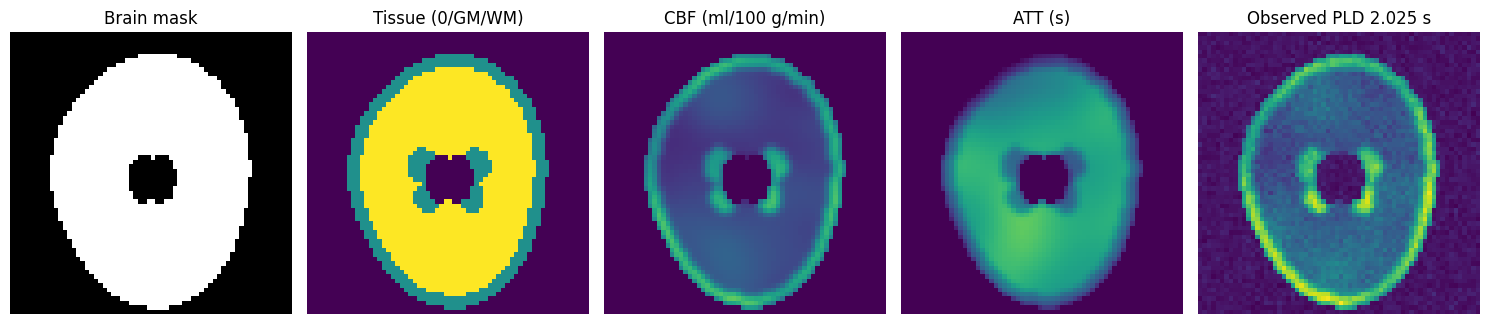

In [5]:
def smooth_field(shape, rng, scale):
    z = ndimage.gaussian_filter(rng.normal(size=shape), sigma=scale)
    return (z - z.mean()) / (z.std() + 1e-8)

def generate_phantom(seed, sample_id, snr, plds=PLDS, shifted=False):
    rng = np.random.default_rng(seed)
    h = w = CONFIG["image_size"]
    y, x = np.mgrid[:h, :w]
    cy = h / 2 + rng.uniform(-1.5, 1.5)
    cx = w / 2 + rng.uniform(-1.5, 1.5)
    ry = h * rng.uniform(0.38, 0.44)
    rx = w * rng.uniform(0.32, 0.38)
    if shifted:
        ry *= rng.uniform(0.86, 1.07)
        rx *= rng.uniform(0.88, 1.12)
    theta = np.arctan2(y - cy, x - cx)
    rfactor = (1.0 + rng.uniform(-0.04, 0.04) * np.cos(2 * theta)
               + rng.uniform(-0.03, 0.03) * np.cos(3 * theta + rng.uniform(0, np.pi))
               + rng.uniform(-0.02, 0.02) * np.cos(4 * theta))
    dist = np.sqrt(((y - cy) / ry)**2 + ((x - cx) / rx)**2) / rfactor
    parenchyma = dist <= 1.0
    vent_y, vent_x = h * rng.uniform(0.08, 0.12), w * rng.uniform(0.04, 0.07)
    ventricles = (np.sqrt(((y-cy)/vent_y)**2 + ((np.abs(x-cx)-2.0)/vent_x)**2) <= 1.0) & parenchyma
    mask = parenchyma & ~ventricles
    border_dist = ndimage.distance_transform_edt(parenchyma)
    cortex = mask & (border_dist <= rng.uniform(2.5, 4.0))
    deep = np.zeros_like(mask)
    for dy, dx, sy, sx in [(-3,-6,4,3.5),(-3,6,4,3.5),(4,-5,3.5,3),(4,5,3.5,3)]:
        deep |= np.sqrt(((y-(cy+dy))/sy)**2 + ((x-(cx+dx))/sx)**2) <= 1.0
    gm = cortex | (deep & mask)
    wm = mask & ~gm
    tissue = np.zeros((h, w), dtype=np.uint8)  # 0 background/CSF, 1 GM, 2 WM
    tissue[gm] = 1
    tissue[wm] = 2

    cbf_field = smooth_field((h, w), rng, 5.0)
    att_field = smooth_field((h, w), rng, 6.0)
    grad = ((y-cy)/(h/2)) * rng.uniform(0.15, 0.35)
    gm_cbf = rng.uniform(58, 70)
    wm_cbf = rng.uniform(20, 28)
    gm_att = rng.uniform(1.0, 1.3)
    wm_att = rng.uniform(1.6, 2.0)
    if shifted:
        gm_cbf -= rng.uniform(5, 12)
        wm_cbf += rng.uniform(4, 9)
        gm_att += rng.uniform(0.25, 0.55)
        wm_att += rng.uniform(0.2, 0.45)
    cbf = np.zeros((h, w), dtype=np.float64)
    att = np.zeros((h, w), dtype=np.float64)
    cbf[gm] = gm_cbf + cbf_field[gm] * rng.uniform(6, 10)
    att[gm] = gm_att + att_field[gm] * rng.uniform(0.1, 0.2) + grad[gm]
    cbf[wm] = wm_cbf + cbf_field[wm] * rng.uniform(3, 6)
    att[wm] = wm_att + att_field[wm] * rng.uniform(0.15, 0.25) + grad[wm]
    cbf_sm, att_sm = ndimage.gaussian_filter(cbf, 0.8), ndimage.gaussian_filter(att, 0.8)
    cbf[mask] = np.clip(cbf_sm[mask], *CONFIG["cbf_bounds"])
    att[mask] = np.clip(att_sm[mask], *CONFIG["att_bounds_s"])

    raw = np.zeros((len(plds), h, w), dtype=np.float64)
    raw[:, mask] = asl_signal_numpy(cbf[mask], att[mask], plds).T
    sigma = CONFIG["signal_reference"] / float(snr)
    signal = noisy_sum_of_ricians(raw, sigma, rng)
    target = np.stack([cbf, att]).astype(np.float32)
    mask_arr = mask[None].astype(np.float32)
    metadata = {
        "sample_id": str(sample_id), "seed": int(seed), "snr": float(snr),
        "sigma": float(sigma), "plds_s": list(map(float, plds)),
        "n_valid_voxels": int(mask.sum()), "shifted": bool(shifted),
        "generation": "reference-like Fourier-perturbed ellipse / GM-WM / ventricles",
        "generation_config": {
            "image_size": h, "cbf_bounds": CONFIG["cbf_bounds"],
            "att_bounds_s": CONFIG["att_bounds_s"], "tau_s": TAU,
            "tissue_T1_s": T1T, "blood_T1_s": T1A, "noise_model": "sum of two independent Rician magnitudes",
        },
    }
    assert signal.shape == (len(plds), h, w)
    assert target.shape == (2, h, w) and mask_arr.shape == (1, h, w)
    assert mask_arr.sum() > 0 and np.isfinite(signal).all() and np.isfinite(target).all()
    assert np.all((target[0][mask] >= 0) & (target[0][mask] <= 100))
    assert np.all((target[1][mask] >= 0.5) & (target[1][mask] <= 3.0))
    return {"x": signal, "y": target, "mask": mask_arr, "tissue": tissue, "metadata": metadata}

def make_split(n, split_seed, split_name, snrs=None, plds=PLDS, shifted=False):
    rng = np.random.default_rng(split_seed)
    choices = CONFIG["train_snr_choices"] if snrs is None else snrs
    out = []
    for i in range(n):
        s = float(rng.choice(choices))
        out.append(generate_phantom(split_seed * 100000 + i, f"{split_name}-{split_seed}-{i}", s,
                                    plds=plds, shifted=shifted))
    return out

demo = generate_phantom(42, "demo-42-0", 15.0)
fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
ax[0].imshow(demo["mask"][0], cmap="gray"); ax[0].set_title("Brain mask")
ax[1].imshow(demo["tissue"], vmin=0, vmax=2, cmap="viridis"); ax[1].set_title("Tissue (0/GM/WM)")
ax[2].imshow(demo["y"][0], vmin=0, vmax=100); ax[2].set_title("CBF (ml/100 g/min)")
ax[3].imshow(demo["y"][1], vmin=0.5, vmax=3); ax[3].set_title("ATT (s)")
ax[4].imshow(demo["x"][1]); ax[4].set_title(f"Observed PLD {PLDS[1]:.3f} s")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
fig.savefig(OUT/"example_spatial_phantom.png",dpi=160,bbox_inches="tight")

### Phantom-generation interpretation

The plotted maps show a known spatially smooth target and separate GM/WM regions; the mask excludes CSF and outside-brain pixels from supervised losses and metrics. This is a synthetic 2-D slice model, not an anatomical MRI dataset. Test phantoms are generated from distinct seeds at the whole-phantom level.

## 6. Independent splits and training-only normalization

Signal normalization uses one scalar mean and standard deviation fitted only to valid training voxels (all PLDs pooled), so the timing-conditioned model can also accept a different count of PLDs. Target means/scales are fitted only on valid training voxels. Validation/test reuse these values unchanged. Physical bounds remain the targets' sampling bounds; predictions are not silently clipped during evaluation.

In [6]:
train_data = make_split(ACTIVE["n_train"], CONFIG["train_seed"], "train")
val_data = make_split(ACTIVE["n_val"], CONFIG["val_seed"], "validation")
test_data = make_split(ACTIVE["n_test"], CONFIG["test_seed"], "test",
                       snrs=CONFIG["test_snr_choices"])
assert set(d["metadata"]["sample_id"] for d in train_data).isdisjoint(
    d["metadata"]["sample_id"] for d in val_data + test_data)

def stack_split(split):
    return {
        "x": np.stack([d["x"] for d in split]),
        "y": np.stack([d["y"] for d in split]),
        "mask": np.stack([d["mask"] for d in split]),
        "tissue": np.stack([d["tissue"] for d in split]),
        "sigma": np.asarray([d["metadata"]["sigma"] for d in split], dtype=np.float32),
        "snr": np.asarray([d["metadata"]["snr"] for d in split], dtype=np.float32),
        "ids": [d["metadata"]["sample_id"] for d in split],
    }
train, val, test = map(stack_split, (train_data, val_data, test_data))
valid_train = train["mask"][:, 0] > 0.5
norm = {
    "x_mean": float(train["x"].transpose(0, 2, 3, 1)[valid_train].mean()),
    "x_std": float(train["x"].transpose(0, 2, 3, 1)[valid_train].std() + 1e-8),
}
norm["y_mean"] = np.array([train["y"][:, c][valid_train].mean() for c in range(2)], np.float32)
norm["y_std"] = np.array([train["y"][:, c][valid_train].std() + 1e-8 for c in range(2)], np.float32)

def normalized_arrays(split):
    xn = ((split["x"] - norm["x_mean"]) / norm["x_std"]).astype(np.float32)
    yn = ((split["y"] - norm["y_mean"][None, :, None, None]) /
          norm["y_std"][None, :, None, None]).astype(np.float32)
    yn = np.where(split["mask"] > 0.5, yn, 0.0).astype(np.float32)
    return xn, yn
for _split in (train, val, test):
    _split["xn"], _split["yn"] = normalized_arrays(_split)
assert len(set(train["ids"]).intersection(val["ids"] + test["ids"])) == 0
assert norm["x_std"] > 0 and np.all(norm["y_std"] > 0)
print("Split sizes:", len(train["ids"]), len(val["ids"]), len(test["ids"]))
print("Training-only normalization:", norm)

Split sizes: 12 4 6
Training-only normalization: {'x_mean': 381.9447021484375, 'x_std': 233.00555419921875, 'y_mean': array([34.82348  ,  1.5276707], dtype=float32), 'y_std': array([14.824216 ,  0.3666966], dtype=float32)}


## 7. Reference spatial U-Net baseline

`ASLUNet` follows the repository's four-channel, two-output U-Net: double Conv-BatchNorm-ReLU blocks, max-pool encoder, transposed-convolution decoder with skip connections, and a 1x1 output layer. The full feature widths are `[32,64,128,256]` plus a 512-channel bottleneck, as in `experiments_unet_4pld/model.py`. Smoke mode narrows widths and is explicitly not an exact reproduction. Full reference training uses AdamW, learning rate `0.001`, weight decay `1e-4`, masked L1, ReduceLROnPlateau, gradient norm clipping at 1, and early stopping.

In [7]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch, mid_ch=None):
        super().__init__()
        mid_ch = mid_ch or out_ch
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 3, padding=1, bias=False), nn.BatchNorm2d(mid_ch), nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__(); self.net = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))
    def forward(self, x): return self.net(x)

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, 2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        dy, dx = skip.size(2) - x.size(2), skip.size(3) - x.size(3)
        x = F.pad(x, [dx//2, dx-dx//2, dy//2, dy-dy//2])
        return self.conv(torch.cat([skip, x], dim=1))

class UNetCore(nn.Module):
    def __init__(self, in_channels, features):
        super().__init__()
        f0, f1, f2, f3 = features
        f4 = 2 * f3
        self.inc = DoubleConv(in_channels, f0)
        self.down1, self.down2 = Down(f0, f1), Down(f1, f2)
        self.down3, self.down4 = Down(f2, f3), Down(f3, f4)
        self.up1, self.up2 = Up(f4, f3), Up(f3, f2)
        self.up3, self.up4 = Up(f2, f1), Up(f1, f0)
        self.out = nn.Conv2d(f0, 2, 1)
    def forward_features(self, x):
        x1 = self.inc(x); x2 = self.down1(x1); x3 = self.down2(x2)
        x4 = self.down3(x3); x5 = self.down4(x4)
        z = self.up1(x5, x4); z = self.up2(z, x3)
        z = self.up3(z, x2); z = self.up4(z, x1)
        return z
    def forward(self, x): return self.out(self.forward_features(x))

class ASLUNet(nn.Module):
    def __init__(self, features):
        super().__init__(); self.core = UNetCore(4, features)
    def forward(self, x): return self.core(x)

baseline_probe = ASLUNet(ACTIVE["features"]).to(DEVICE)
with torch.no_grad():
    _y = baseline_probe(torch.zeros(1, 4, 64, 64, device=DEVICE))
assert _y.shape == (1, 2, 64, 64) and torch.isfinite(_y).all()
nparams_baseline = sum(p.numel() for p in baseline_probe.parameters() if p.requires_grad)
print(baseline_probe)
print(f"Baseline trainable parameters ({ACTIVE['features']}): {nparams_baseline:,}")
print("Full-reference-width parameter count is computed below independently of smoke width.")
_full_probe = ASLUNet([32, 64, 128, 256])
print(f"Reference-width trainable parameters: {sum(p.numel() for p in _full_probe.parameters()):,}")
del baseline_probe, _full_probe

ASLUNet(
  (core): UNetCore(
    (inc): DoubleConv(
      (net): Sequential(
        (0): Conv2d(4, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
    (down1): Down(
      (net): Sequential(
        (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (1): DoubleConv(
          (net): Sequential(
            (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): ReLU(inplace=True)
            (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), pad

## 8. Identifiability diagnosis before guided architecture

For `theta=[CBF,ATT]`, the Jacobian is computed numerically from the high-SNR observation approximation `S=2*SCALE*ASL`. Parameters are scaled by their full physical ranges (100 ml/100 g/min, 2.5 s) before singular values are interpreted. A noise-weighted information matrix is `F=J_scaled.T J_scaled/(2 sigma^2)`, using the high-SNR variance approximation for the sum of Rician magnitudes. This is approximate, not an exact likelihood/Fisher matrix for the Rician-sum distribution.

We define the local identifiability index as `sqrt(lambda_min(F))`: a lower value means at least one scaled parameter direction has less local signal information at the declared noise level. Near-singular cases are retained as zero rather than hidden by division.

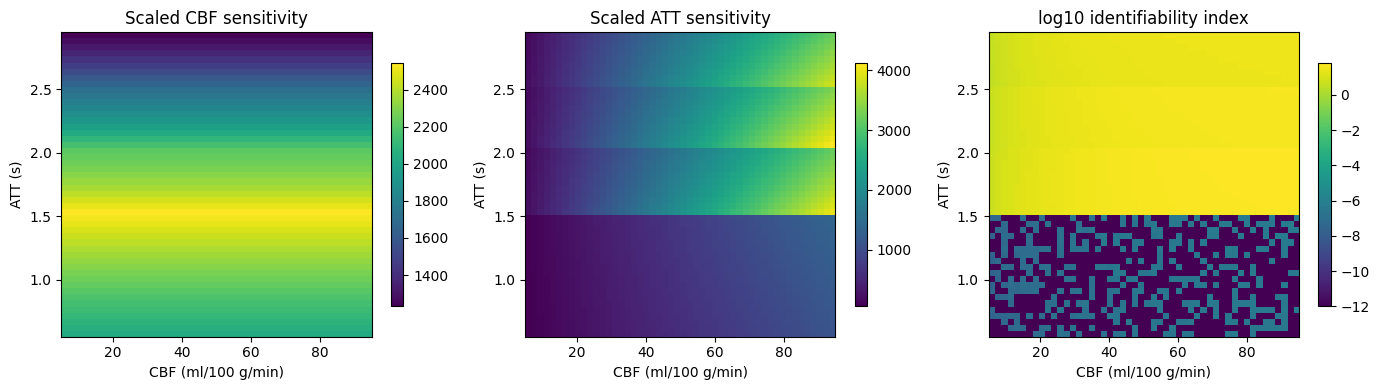

Near-singular grid points (index < 1e-6): 1000 / 2500


,timing,SNR,min_singular,max_singular
0,reference four PLDs,5.0,0.000000e+00,28.131031
1,reference four PLDs,10.0,0.000000e+00,56.262061
2,reference four PLDs,20.0,0.000000e+00,112.524123
3,early four PLDs,5.0,2.337680e+01,44.562764
4,early four PLDs,10.0,4.675360e+01,89.125527
5,early four PLDs,20.0,9.350721e+01,178.251054
6,late four PLDs,5.0,0.000000e+00,16.028578
7,late four PLDs,10.0,0.000000e+00,32.057156
8,late four PLDs,20.0,0.000000e+00,64.114313
9,three PLDs,5.0,8.429370e-08,27.445740


In [8]:
def jacobian_and_information(cbf, att, plds=PLDS, sigma=CONFIG["signal_reference"]/15.0):
    c_eps, a_eps = 1e-2, 1e-4
    d_c = (2*asl_signal_numpy(cbf+c_eps, att, plds) -
           2*asl_signal_numpy(cbf-c_eps, att, plds)) / (2*c_eps) * 100.0
    d_a = (2*asl_signal_numpy(cbf, att+a_eps, plds) -
           2*asl_signal_numpy(cbf, att-a_eps, plds)) / (2*a_eps) * 2.5
    j = np.stack([d_c, d_a], axis=-1)
    jw = j / (math.sqrt(2.0) * float(sigma))
    fisher = np.einsum("...li,...lj->...ij", jw, jw)
    eig = np.linalg.eigvalsh(fisher)
    eig = np.maximum(eig, 0.0)
    return j, fisher, np.sqrt(eig[..., 0]), np.sqrt(eig[..., 1])

cbf_axis = np.linspace(5, 95, 50)
att_axis = np.linspace(0.55, 2.95, 50)
CBF_GRID, ATT_GRID = np.meshgrid(cbf_axis, att_axis)
JGRID, FGRID, INFO_MIN, INFO_MAX = jacobian_and_information(
    CBF_GRID, ATT_GRID, PLDS, CONFIG["signal_reference"]/15.0)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
im0 = ax[0].imshow(np.linalg.norm(JGRID[..., 0], axis=-1), origin="lower",
                   extent=[cbf_axis.min(), cbf_axis.max(), att_axis.min(), att_axis.max()], aspect="auto")
ax[0].set(title="Scaled CBF sensitivity", xlabel="CBF (ml/100 g/min)", ylabel="ATT (s)")
im1 = ax[1].imshow(np.linalg.norm(JGRID[..., 1], axis=-1), origin="lower",
                   extent=[cbf_axis.min(), cbf_axis.max(), att_axis.min(), att_axis.max()], aspect="auto")
ax[1].set(title="Scaled ATT sensitivity", xlabel="CBF (ml/100 g/min)", ylabel="ATT (s)")
im2 = ax[2].imshow(np.log10(INFO_MIN + 1e-12), origin="lower",
                   extent=[cbf_axis.min(), cbf_axis.max(), att_axis.min(), att_axis.max()], aspect="auto")
ax[2].set(title="log10 identifiability index", xlabel="CBF (ml/100 g/min)", ylabel="ATT (s)")
for a, im in zip(ax, [im0, im1, im2]): fig.colorbar(im, ax=a, shrink=.8)
plt.tight_layout(); plt.show()
fig.savefig(OUT/"identifiability_parameter_map.png",dpi=160,bbox_inches="tight")
print("Near-singular grid points (index < 1e-6):", int(np.sum(INFO_MIN < 1e-6)), "/", INFO_MIN.size)

# Timing and noise alter information; same points and parameter scaling.
timing_sets = {
    "reference four PLDs": PLDS,
    "early four PLDs": np.array([0.8, 1.2, 1.6, 2.0]),
    "late four PLDs": np.array([2.2, 2.7, 3.2, 3.7]),
    "three PLDs": PLDS[:3],
}
info_rows = []
for name, times in timing_sets.items():
    for snr in [5.0, 10.0, 20.0]:
        _, _, vmin, vmax = jacobian_and_information(55.0, 1.5, times,
                                                    CONFIG["signal_reference"]/snr)
        info_rows.append({"timing": name, "SNR": snr, "min_singular": float(vmin),
                          "max_singular": float(vmax)})
timing_information = pd.DataFrame(info_rows)
display(timing_information)

### Identifiability interpretation

Sensitivity and information plots describe this forward model and the stated noise approximation only. The diagnostic by itself does not justify a better estimator. Later, the notebook aggregates ATT errors by phantom and tests whether phantom-level information predicts errors; correlated pixels are never counted as independent subjects.

## 9. IA-ASLNet prototype and losses

IA-ASLNet is deliberately a testable prototype, not a novelty claim. It embeds each `(signal, PLD)` pair with shared convolutions, pools across PLDs, and feeds explicit timing summary metadata through a FiLM transformation before the spatial U-Net. Because PLD processing is shared, it accepts a variable number of PLDs (`L>=2`) when actual times are supplied; the baseline remains fixed to four input channels. Generalization is only claimed for timing configurations actually tested.

Optional guidance computes a local, noise-weighted Jacobian around the current physical predictions and gates a bounded learned residual by `1-r`, where `r=lambda_min/(lambda_min+1)` is the information relative to a unit standardized prior precision. Gradients flow through the predicted signal derivatives and gate; clipping in the local Jacobian evaluation handles out-of-bound interim estimates, while raw final predictions remain un-clipped. This interpretation is approximate because the noise is sum-of-Rician, and known sigma is simulation metadata.

Supervised CBF and ATT losses are separate masked L1 terms in training-standardized units. An optional signal-domain consistency term compares the observation with `2*noiseless_signal`; it is only a high-SNR squared-error approximation, **not** an exact Rician-sum likelihood. It is off by default.

c:\Users\ANU THOMSON\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\autograd\graph.py:825: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\Context.cpp:208.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


IA-ASLNet supports the tested L=3 input; gradient and shape checks passed.
Baseline parameters: 486634
Timing-conditioned parameters: 488492
Forward path: [B,L,H,W]+[B,L] -> shared PLD encoder -> mean/max -> FiLM -> U-Net -> CBF/ATT


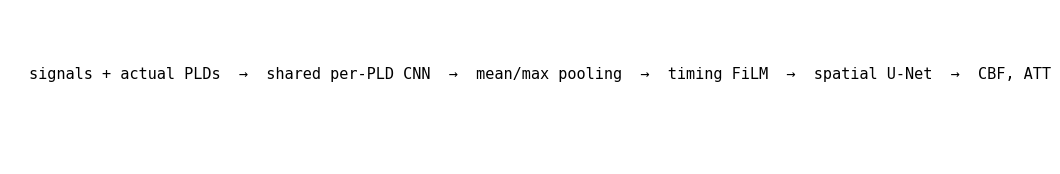

In [9]:
def identifiability_torch(cbf, att, plds, sigma):
    # Inputs [B,H,W]; output reliability [B,1,H,W], detached is intentionally not used.
    cb = cbf.clamp(0.0, 100.0)
    at = att.clamp(0.5, 3.0)
    dc, da = 0.05, 0.001
    jc = (asl_signal_torch((cb+dc), at, plds) -
          asl_signal_torch((cb-dc), at, plds)) / (2*dc) * 100.0
    ja = (asl_signal_torch(cb, (at+da), plds) -
          asl_signal_torch(cb, (at-da), plds)) / (2*da) * 2.5
    scale_noise = (math.sqrt(2.0) * sigma[:, None, None, None]).clamp_min(1e-6)
    jc, ja = jc/scale_noise, ja/scale_noise
    a = (jc*jc).sum(dim=1)
    b = (jc*ja).sum(dim=1)
    c = (ja*ja).sum(dim=1)
    disc = torch.sqrt(torch.clamp((a-c)**2 + 4*b*b, min=1e-12))
    eig_min = torch.clamp((a+c-disc)/2.0, min=0.0)
    return eig_min[:, None] / (eig_min[:, None] + 1.0)

class TimingConditionedASLNet(nn.Module):
    def __init__(self, features, use_guidance=False):
        super().__init__()
        base = features[0]
        self.use_guidance = use_guidance
        self.pld_encoder = nn.Sequential(
            nn.Conv2d(2, base, 3, padding=1), nn.BatchNorm2d(base), nn.ReLU(inplace=True),
            nn.Conv2d(base, base, 3, padding=1), nn.BatchNorm2d(base), nn.ReLU(inplace=True))
        self.timing_film = nn.Sequential(nn.Linear(5, 4*base), nn.Tanh())
        self.core = UNetCore(2*base, features)
        self.residual = nn.Conv2d(2*base, 2, 1)

    def forward(self, x, plds, sigma=None):
        # x [B,L,H,W] normalized using training scalar stats; plds [B,L] in seconds.
        if x.ndim != 4 or plds.ndim != 2 or x.shape[:2] != plds.shape:
            raise ValueError(f"Expected x [B,L,H,W], plds [B,L]; got {x.shape}, {plds.shape}")
        b, n, h, w = x.shape
        if n < 2: raise ValueError("At least two PLDs are required.")
        pld_norm = (plds - 2.0) / 1.0
        enc_in = torch.stack([x, pld_norm[:, :, None, None].expand(-1,-1,h,w)], dim=2)
        enc = self.pld_encoder(enc_in.reshape(b*n, 2, h, w)).reshape(b, n, -1, h, w)
        pooled = torch.cat([enc.mean(dim=1), enc.amax(dim=1)], dim=1)
        tfeat = torch.stack([
            pld_norm.mean(1), pld_norm.std(1, unbiased=False),
            pld_norm.amin(1), pld_norm.amax(1),
            torch.full_like(pld_norm.mean(1), float(n)/4.0)], dim=1)
        gamma_beta = self.timing_film(tfeat)
        gamma, beta = gamma_beta.chunk(2, dim=1)
        conditioned = pooled * (1.0 + gamma[:, :, None, None]) + beta[:, :, None, None]
        feat = self.core.forward_features(conditioned)
        pred = self.core.out(feat)
        if self.use_guidance:
            if sigma is None: raise ValueError("Noise sigma metadata is required for guidance.")
            cbf = pred[:, 0] * norm["y_std"][0] + norm["y_mean"][0]
            att = pred[:, 1] * norm["y_std"][1] + norm["y_mean"][1]
            reliability = identifiability_torch(cbf, att, plds, sigma)
            pred = pred + torch.tanh(self.residual(conditioned)) * (1.0 - reliability)
        return pred

def masked_channel_loss(pred, target, mask):
    m = mask.expand_as(pred)
    denom = m.sum(dim=(0,2,3)).clamp_min(1.0)
    if CONFIG["mode"] == "optimized":
        error = (pred-target).square()
    else:
        error = (pred-target).abs()
    return (error*m).sum(dim=(0,2,3)) / denom

def physics_consistency_loss(pred_norm, x_raw, mask, plds, sigma=None):
    cbf = pred_norm[:,0]*norm["y_std"][0]+norm["y_mean"][0]
    att = pred_norm[:,1]*norm["y_std"][1]+norm["y_mean"][1]
    expected = 2.0 * asl_signal_torch(cbf, att, plds)
    # Normalize signal units; masked L1 is a transparent signal-domain approximation.
    m = mask.expand_as(x_raw)
    return (((expected-x_raw)/CONFIG["signal_reference"]).abs()*m).sum()/m.sum().clamp_min(1.0)

# Variable PLD count smoke check and gradient checks.
ia_probe = TimingConditionedASLNet(ACTIVE["features"]).to(DEVICE)
pld_probe = torch.tensor([[1.4, 2.0, 2.8]], dtype=torch.float32, device=DEVICE)
x_probe = torch.randn(1, 3, 64, 64, device=DEVICE, requires_grad=True)
y_probe = ia_probe(x_probe, pld_probe)
assert y_probe.shape == (1,2,64,64) and torch.isfinite(y_probe).all()
y_probe.square().mean().backward()
assert x_probe.grad is not None and x_probe.grad.abs().sum() > 0
assert sum(p.numel() for p in ia_probe.parameters()) > 0
guided_probe=TimingConditionedASLNet(ACTIVE["features"],use_guidance=True).to(DEVICE)
guided_out=guided_probe(x_probe.detach(),pld_probe,torch.tensor([20.0],device=DEVICE))
guided_out.abs().mean().backward()
assert torch.isfinite(guided_out).all()
cbf_check=torch.full((1,4,4),50.0,device=DEVICE,requires_grad=True)
att_check=torch.full((1,4,4),1.5,device=DEVICE,requires_grad=True)
physics_check=asl_signal_torch(cbf_check,att_check,
    torch.tensor(PLDS,dtype=torch.float32,device=DEVICE)[None]).square().mean()
physics_check.backward()
assert cbf_check.grad is not None and cbf_check.grad.abs().sum()>0
assert att_check.grad is not None and att_check.grad.abs().sum()>0
print("IA-ASLNet supports the tested L=3 input; gradient and shape checks passed.")
print("Baseline parameters:", sum(p.numel() for p in ASLUNet(ACTIVE["features"]).parameters()))
print("Timing-conditioned parameters:", sum(p.numel() for p in ia_probe.parameters()))
print("Forward path: [B,L,H,W]+[B,L] -> shared PLD encoder -> mean/max -> FiLM -> U-Net -> CBF/ATT")
plt.figure(figsize=(12,2))
plt.text(.02,.55,"signals + actual PLDs  →  shared per-PLD CNN  →  mean/max pooling  →  timing FiLM  →  spatial U-Net  →  CBF, ATT",
         fontsize=11, family="monospace")
plt.axis("off"); plt.show()
del ia_probe
del guided_probe

## 10. Matched training, checkpointing, and training curves

Both models use the same independent phantoms, training-only normalization, optimizer settings, masked supervision, and early-stopping rule. The baseline receives the four normalized channels; IA-ASLNet receives those same signals plus the actual PLD vector. Best checkpoints are restored for evaluation; a latest completed-epoch checkpoint supports resuming interrupted runs. Set `resume=True` to continue from that state. The optional physics term is reported separately and has zero default weight.

Smoke settings are a pipeline check, not evidence for a final scientific result. The optimized setting increases independent training phantoms/epochs, includes varied SNRs in training, and uses masked standardized MSE weighted toward CBF RMSE (default CBF weight 4, ATT weight 1), with moderately wider features. It is an exploratory tuning run, not an exact baseline reproduction. The full configuration uses reference width/data scale and optimizer but a conservative batch size of 2 (versus reference 32).

In [10]:
def make_loader(split, batch_size, shuffle):
    x = torch.from_numpy(split["xn"])
    y = torch.from_numpy(split["yn"])
    m = torch.from_numpy(split["mask"])
    sig = torch.from_numpy(split["sigma"])
    raw = torch.from_numpy(split["x"])
    return DataLoader(TensorDataset(x,y,m,sig,raw), batch_size=batch_size,
                      shuffle=shuffle, num_workers=0, pin_memory=torch.cuda.is_available())

train_loader = make_loader(train, ACTIVE["batch_size"], True)
val_loader = make_loader(val, ACTIVE["batch_size"], False)
PHYSICS_WEIGHT = float(CONFIG["physics_weight"])

def model_call(model, kind, xb, sigma, plds):
    if kind == "baseline": return model(xb)
    return model(xb, plds, sigma)

def run_epoch(model, kind, loader, optimizer=None, physics_weight=0.0):
    is_train = optimizer is not None
    model.train(is_train)
    sums = np.zeros(4, dtype=np.float64)  # cbf, att, physics, total
    n_batches = 0
    for xb,yb,mb,sig,raw in loader:
        xb,yb,mb,sig,raw = [v.to(DEVICE, non_blocking=True) for v in (xb,yb,mb,sig,raw)]
        plds = torch.tensor(PLDS, dtype=xb.dtype, device=DEVICE).expand(xb.shape[0], -1)
        if is_train: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_train):
            pred = model_call(model,kind,xb,sig,plds)
            if not torch.isfinite(pred).all(): raise FloatingPointError("Non-finite model output.")
            lc,la = masked_channel_loss(pred,yb,mb)
            lp = (physics_consistency_loss(pred,raw,mb,plds,sig)
                  if physics_weight else pred.new_zeros(()))
            if CONFIG["mode"] == "optimized":
                cbf_weight = float(CONFIG["optimized_cbf_loss_weight"])
                total = (cbf_weight*lc + la)/(cbf_weight+1.0) + physics_weight*lp
            else:
                total = 0.5*(lc+la) + physics_weight*lp
            if is_train:
                total.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        sums += [float(lc.detach()),float(la.detach()),float(lp.detach()),float(total.detach())]
        n_batches += 1
    return dict(zip(["cbf_loss","att_loss","physics_loss","total_loss"], sums/max(n_batches,1)))

def fit_model(kind, seed=42, guidance=False, physics_weight=0.0, tag=None):
    set_seed(seed)
    model = (ASLUNet(ACTIVE["features"]) if kind=="baseline" else
             TimingConditionedASLNet(ACTIVE["features"], use_guidance=guidance)).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["learning_rate"],
                                  weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=CONFIG["lr_factor"],
        patience=CONFIG["lr_patience"], min_lr=CONFIG["min_lr"])
    name = tag or kind
    ckpt_path = OUT / f"{name}_seed{seed}_best.pt"
    latest_path = OUT / f"{name}_seed{seed}_latest.pt"
    best, best_epoch, bad = float("inf"), 0, 0
    history, start_epoch = [], 1
    if CONFIG["resume"]:
        if not latest_path.exists():
            raise FileNotFoundError(f"Resume requested but no completed-epoch checkpoint exists: {latest_path}")
        state = torch.load(latest_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        best, best_epoch, bad = state["best"], state["best_epoch"], state["bad_epochs"]
        history, start_epoch = state["history"], state["epoch"] + 1
        print("Resumed", latest_path, "at next epoch", start_epoch)
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    for epoch in range(start_epoch, ACTIVE["epochs"]+1):
        tr = run_epoch(model,kind,train_loader,optimizer,physics_weight)
        with torch.no_grad():
            va = run_epoch(model,kind,val_loader,None,physics_weight)
        scheduler.step(va["total_loss"])
        row = {"epoch":epoch, "lr":optimizer.param_groups[0]["lr"],
               **{f"train_{k}":v for k,v in tr.items()},
               **{f"val_{k}":v for k,v in va.items()}}
        history.append(row)
        print(f"{name} epoch {epoch:02d}: train={tr['total_loss']:.4f}, val={va['total_loss']:.4f}")
        if not np.isfinite(va["total_loss"]): raise FloatingPointError("Non-finite validation loss.")
        if va["total_loss"] < best:
            best,best_epoch,bad = va["total_loss"],epoch,0
            torch.save({"model":model.state_dict(),"optimizer":optimizer.state_dict(),
                        "epoch":epoch,"best":best,"seed":seed,"kind":kind,
                        "guidance":guidance,"physics_weight":physics_weight,
                        "norm":{"x_mean":norm["x_mean"],"x_std":norm["x_std"],
                                "y_mean":norm["y_mean"].tolist(),"y_std":norm["y_std"].tolist()},
                        "config":CONFIG}, ckpt_path)
        else:
            bad += 1
        torch.save({"model":model.state_dict(),"optimizer":optimizer.state_dict(),
                    "scheduler":scheduler.state_dict(),"epoch":epoch,"best":best,
                    "best_epoch":best_epoch,"bad_epochs":bad,"history":history,
                    "seed":seed,"kind":kind,"guidance":guidance,
                    "physics_weight":physics_weight,"config":CONFIG},latest_path)
        if bad >= ACTIVE["patience"]: break
    state = torch.load(ckpt_path,map_location=DEVICE,weights_only=False)
    model.load_state_dict(state["model"])
    history_df = pd.DataFrame(history)
    history_df.to_csv(OUT/f"{name}_seed{seed}_history.csv",index=False)
    return {"model":model,"history":history_df,"seconds":time.perf_counter()-t0,
            "best_epoch":best_epoch,"checkpoint":str(ckpt_path),
            "peak_gpu_memory_bytes":int(torch.cuda.max_memory_allocated()) if torch.cuda.is_available() else None,
            "parameters":sum(p.numel() for p in model.parameters() if p.requires_grad)}

training_results = {}
selected_seeds = CONFIG["seeds"] if CONFIG["run_three_seeds"] else CONFIG["seeds"][:1]
for seed in selected_seeds:
    suffix = "" if seed == selected_seeds[0] else f"_seed{seed}"
    training_results["baseline" + suffix] = fit_model(
        "baseline", seed, tag="baseline" + suffix)
    training_results["ia_timing" + suffix] = fit_model(
        "ia", seed, guidance=False, physics_weight=PHYSICS_WEIGHT, tag="ia_timing" + suffix)
print("Training wall times:", {k:round(v["seconds"],1) for k,v in training_results.items()})

baseline epoch 01: train=0.8533, val=0.8608
baseline epoch 02: train=0.6411, val=0.8461


c:\Users\ANU THOMSON\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\autograd\graph.py:825: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\Context.cpp:208.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


ia_timing epoch 01: train=0.7466, val=0.8484
ia_timing epoch 02: train=0.5031, val=0.8159
Training wall times: {'baseline': 1.4, 'ia_timing': 1.4}


### Training interpretation

The printed and saved histories are computed from this run. Short smoke training can underfit; no metric from it should be presented as definitive. The best validation checkpoint, not the last epoch, is used for evaluation.

## 11. Matched evaluation and identifiability/error analysis

Metrics are calculated inside each phantom's valid brain mask. Each phantom is the independent aggregation unit; the aggregate table reports mean and standard deviation of per-phantom values. Predictions are left raw (no evaluation clipping). The baseline and IA model use exactly the same test IDs.

In [11]:
INFERENCE_SECONDS_PER_PHANTOM = {}
def predict_split(model, kind, split):
    model.eval()
    pred_parts = []
    if torch.cuda.is_available(): torch.cuda.synchronize()
    tic=time.perf_counter()
    with torch.no_grad():
        for i in range(0,len(split["ids"]),ACTIVE["batch_size"]):
            xb=torch.from_numpy(split["xn"][i:i+ACTIVE["batch_size"]]).to(DEVICE)
            sig=torch.from_numpy(split["sigma"][i:i+ACTIVE["batch_size"]]).to(DEVICE)
            plds=torch.tensor(PLDS,dtype=xb.dtype,device=DEVICE).expand(xb.shape[0],-1)
            out=model_call(model,kind,xb,sig,plds)
            pred_parts.append(out.cpu().numpy())
    if torch.cuda.is_available(): torch.cuda.synchronize()
    INFERENCE_SECONDS_PER_PHANTOM[id(model)] = (time.perf_counter()-tic)/max(len(split["ids"]),1)
    predn=np.concatenate(pred_parts,axis=0)
    return predn*norm["y_std"][None,:,None,None]+norm["y_mean"][None,:,None,None]

def per_phantom_metrics(split,pred,model_name,seed=None,model_object=None):
    rows=[]
    for i in range(len(split["ids"])):
        m=split["mask"][i,0]>0.5
        p=pred[i]
        truth=split["y"][i]
        row={"sample_id":split["ids"][i],"model":model_name,"seed":seed,
             "snr":float(split["snr"][i]),
             "sigma":float(split["sigma"][i]),"gm_fraction":float((split["tissue"][i][m]==1).mean()),
             "wm_fraction":float((split["tissue"][i][m]==2).mean()),
             "inference_seconds_per_phantom":INFERENCE_SECONDS_PER_PHANTOM.get(id(model_object),np.nan),
             "parameter_count":sum(p.numel() for p in model_object.parameters() if p.requires_grad)
                if model_object is not None else np.nan,
             "mean_cbf":float(truth[0][m].mean()),"mean_att":float(truth[1][m].mean())}
        for ci,name in [(0,"cbf"),(1,"att")]:
            err=p[ci][m]-truth[ci][m]
            row[f"{name}_rmse"]=float(np.sqrt(np.mean(err**2)))
            row[f"{name}_mae"]=float(np.mean(np.abs(err)))
            row[f"{name}_bias"]=float(np.mean(err))
            tvals,pvals=truth[ci][m],p[ci][m]
            row[f"{name}_pearson_r"]=float(np.corrcoef(tvals,pvals)[0,1]) if tvals.std()>0 and pvals.std()>0 else np.nan
            covariance=float(np.mean((tvals-tvals.mean())*(pvals-pvals.mean())))
            denom=float(tvals.var()+pvals.var()+(tvals.mean()-pvals.mean())**2)
            row[f"{name}_ccc"]=float(2*covariance/denom) if denom>0 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

BASELINE_KEY = "baseline"
IA_KEY = "ia_timing"
baseline_pred = predict_split(training_results[BASELINE_KEY]["model"],"baseline",test)
ia_pred = predict_split(training_results[IA_KEY]["model"],"ia",test)
assert test["ids"] == [d["metadata"]["sample_id"] for d in test_data]
assert baseline_pred.shape == ia_pred.shape == test["y"].shape
metric_frames=[]
for model_key,result in training_results.items():
    kind = "baseline" if model_key.startswith("baseline") else "ia"
    pred = baseline_pred if model_key == BASELINE_KEY else ia_pred if model_key == IA_KEY else predict_split(result["model"],kind,test)
    seed = CONFIG["seeds"][0] if model_key in (BASELINE_KEY,IA_KEY) else int(model_key.rsplit("_seed",1)[1])
    metric_frames.append(per_phantom_metrics(test,pred,model_key,seed,result["model"]))
metrics = pd.concat(metric_frames,ignore_index=True)
summary = metrics.groupby("model")[[
    "att_rmse","att_mae","att_bias","att_pearson_r","att_ccc",
    "cbf_rmse","cbf_mae","cbf_bias","cbf_pearson_r","cbf_ccc"]].agg(["mean","std"])
display(summary)
display(metrics)
paired_rows=[]
model_names=set(metrics["model"])
for base_key in [k for k in model_names if k=="baseline" or k.startswith("baseline_seed")]:
    suffix=base_key[len("baseline"):]
    ia_key="ia_timing"+suffix
    if ia_key not in model_names: continue
    pair=metrics[metrics.model.isin([base_key,ia_key])].pivot(index="sample_id",columns="model",values="att_rmse")
    delta=(pair[ia_key]-pair[base_key]).dropna().to_numpy()
    rng_ci=np.random.default_rng(2026)
    boot=np.array([rng_ci.choice(delta,size=len(delta),replace=True).mean() for _ in range(2000)])
    paired_rows.append({"seed_pair":suffix or "_seed42","n_phantoms":len(delta),
                        "mean_IA_minus_baseline_ATT_RMSE_s":float(delta.mean()),
                        "bootstrap_95pct_low":float(np.quantile(boot,.025)),
                        "bootstrap_95pct_high":float(np.quantile(boot,.975))})
paired_comparison=pd.DataFrame(paired_rows)
display(paired_comparison)

# Phantom-level identifiability predictor and stratified summaries.
info_rows=[]
for i in range(len(test["ids"])):
    m=test["mask"][i,0]>0.5
    _,_,imin,_=jacobian_and_information(test["y"][i,0][m],test["y"][i,1][m],
                                         PLDS,test["sigma"][i])
    info_rows.append({"sample_id":test["ids"][i],"median_info":float(np.median(imin))})
info_df=pd.DataFrame(info_rows)
ia_ph=metrics[metrics.model==IA_KEY].merge(info_df,on="sample_id")
identifiability_association_text="Insufficient independent phantoms to estimate an error-identifiability association."
if len(ia_ph)>=4:
    rho,pval=stats.spearmanr(ia_ph["median_info"],ia_ph["att_rmse"])
    print(f"Phantom-level Spearman(info, ATT RMSE)={rho:.3f}, p={pval:.3g}; n={len(ia_ph)} phantoms.")
    if len(ia_ph)>=30:
        nuisance=np.column_stack([np.ones(len(ia_ph)),ia_ph["snr"],ia_ph["mean_att"],
                                  ia_ph["mean_cbf"],ia_ph["gm_fraction"]])
        rx=ia_ph["median_info"].to_numpy()-nuisance@np.linalg.lstsq(nuisance,ia_ph["median_info"],rcond=None)[0]
        ry=ia_ph["att_rmse"].to_numpy()-nuisance@np.linalg.lstsq(nuisance,ia_ph["att_rmse"],rcond=None)[0]
        partial=float(np.corrcoef(rx,ry)[0,1]) if rx.std()>0 and ry.std()>0 else float("nan")
        print(f"Linear nuisance-adjusted phantom-level correlation (SNR, mean ATT/CBF, GM fraction): {partial:.3f}")
        identifiability_association_text=(
            f"Phantom-level Spearman rho={rho:.4f}, p={pval:.4g}, n={len(ia_ph)}; "
            f"nuisance-adjusted linear correlation={partial:.4f} (SNR, mean ATT/CBF, GM fraction)."
        )
    else:
        partial=float("nan")
        print("Too few phantoms for a stable nuisance-adjusted model; no adjusted coefficient reported.")
        identifiability_association_text=(
            f"Phantom-level Spearman rho={rho:.4f}, p={pval:.4g}, n={len(ia_ph)}; "
            "too few phantoms for the predeclared nuisance-adjusted model."
        )
    print("Small n and correlated nuisance variables make these descriptive, not confirmatory.")
else:
    print("Too few independent test phantoms for a useful error-identifiability association.")
stratified_rows=[]
for i in range(len(test["ids"])):
    for tissue_id,tissue_name in [(1,"GM"),(2,"WM")]:
        m=(test["mask"][i,0]>0.5)&(test["tissue"][i]==tissue_id)
        if not m.any(): continue
        err=ia_pred[i,1][m]-test["y"][i,1][m]
        att_mean=float(test["y"][i,1][m].mean())
        cbf_mean=float(test["y"][i,0][m].mean())
        stratified_rows.append({
            "sample_id":test["ids"][i],"tissue":tissue_name,
            "snr_band":"low" if test["snr"][i]<=10 else "higher",
            "att_band":"lower" if att_mean<1.5 else "higher",
            "cbf_band":"lower" if cbf_mean<45 else "higher",
            "pld_configuration":"reference_four",
            "att_rmse":float(np.sqrt(np.mean(err**2))),
            "att_mae":float(np.mean(np.abs(err))),"att_bias":float(err.mean()),
        })
stratified_metrics=pd.DataFrame(stratified_rows)
stratified_summary=stratified_metrics.groupby(
    ["snr_band","att_band","cbf_band","tissue","pld_configuration"])[
    ["att_rmse","att_mae","att_bias"]].agg(["mean","std"]).reset_index()

att_rmse            att_mae            att_bias            \
               mean       std     mean       std      mean       std   
model                                                                  
baseline   0.376055  0.055503  0.30663  0.057374  0.014818  0.101091   
ia_timing  0.370416  0.058043  0.31135  0.058841 -0.033626  0.099732   

          att_pearson_r             att_ccc             cbf_rmse            \
                   mean       std      mean       std       mean       std   
model                                                                        
baseline       0.557742  0.076041  0.028369  0.007420  13.523554  1.897436   
ia_timing      0.659402  0.079615  0.061974  0.011262  13.626546  2.302782   

             cbf_mae            cbf_bias           cbf_pearson_r            \
                mean       std      mean       std          mean       std   
model                                                                        
baseline   11.957039  1.702984  2.586182  2.137109      0.763318  0.050740   
ia_timing   9.991479  1.937416 -4.072467  2.142240      0.782546  0.044897   

            cbf_ccc            
               mean       std  
model                          
baseline   0.026887  0.004398  
ia_timing  0.055500  0.004758

,sample_id,model,seed,snr,sigma,gm_fraction,wm_fraction,inference_seconds_per_phantom,parameter_count,mean_cbf,...,cbf_rmse,cbf_mae,cbf_bias,cbf_pearson_r,cbf_ccc,att_rmse,att_mae,att_bias,att_pearson_r,att_ccc
0,test-7-0,baseline,42,15.0,22.28026,0.316394,0.683606,0.006617,486634,35.293968,...,11.719398,9.862691,1.043897,0.764797,0.032403,0.374461,0.314872,-0.069859,0.611948,0.033397
1,test-7-1,baseline,42,15.0,22.28026,0.248935,0.751065,0.006617,486634,32.166904,...,10.988372,9.999895,4.080709,0.668173,0.023639,0.443052,0.381569,-0.108085,0.580287,0.021790
2,test-7-2,baseline,42,15.0,22.28026,0.261322,0.738678,0.006617,486634,31.831123,...,12.973817,11.773036,4.472539,0.758231,0.023062,0.304266,0.234286,0.000793,0.544805,0.031298
3,test-7-3,baseline,42,15.0,22.28026,0.329934,0.670066,0.006617,486634,34.071590,...,15.281708,13.706736,2.290999,0.808034,0.029031,0.316308,0.243039,0.068293,0.458150,0.028286
4,test-7-4,baseline,42,15.0,22.28026,0.329670,0.670330,0.006617,486634,37.158348,...,15.199794,12.977259,-0.772741,0.803226,0.030856,0.408128,0.340286,0.022625,0.661474,0.037656
5,test-7-5,baseline,42,15.0,22.28026,0.309245,0.690755,0.006617,486634,31.902395,...,14.978233,13.422618,4.401690,0.777449,0.022329,0.410112,0.325728,0.175142,0.489786,0.017790
6,test-7-0,ia_timing,42,15.0,22.28026,0.316394,0.683606,0.007539,488492,35.293968,...,12.756468,8.496283,-5.665505,0.817734,0.060344,0.379224,0.324614,-0.116992,0.725787,0.066897
7,test-7-1,ia_timing,42,15.0,22.28026,0.248935,0.751065,0.007539,488492,32.166904,...,10.358508,7.308560,-2.638086,0.758596,0.059767,0.450400,0.395205,-0.156473,0.725004,0.050675
8,test-7-2,ia_timing,42,15.0,22.28026,0.261322,0.738678,0.007539,488492,31.831123,...,12.195872,9.158131,-2.212193,0.745314,0.054771,0.302231,0.246883,-0.047587,0.641647,0.068294
9,test-7-3,ia_timing,42,15.0,22.28026,0.329934,0.670066,0.007539,488492,34.071590,...,15.501249,11.958028,-4.313559,0.787390,0.054427,0.303233,0.242043,0.020156,0.585304,0.070919


,seed_pair,n_phantoms,mean_IA_minus_baseline_ATT_RMSE_s,bootstrap_95pct_low,bootstrap_95pct_high
0,_seed42,6,-0.005639,-0.014954,0.002268


Phantom-level Spearman(info, ATT RMSE)=0.314, p=0.544; n=6 phantoms.
Too few phantoms for a stable nuisance-adjusted model; no adjusted coefficient reported.
Small n and correlated nuisance variables make these descriptive, not confirmatory.


## 12. Locked robustness tests and ablations

Stress phantoms use independent seeds, are generated only after model selection/training, and are never used for early stopping. The stress table includes lower SNR, an unseen SNR, altered physiology/morphology, combined shifts, and a four-PLD timing shift. Fixed-channel baseline U-Net and IA-ASLNet can both evaluate the shifted four-PLD sets; only IA-ASLNet supports a different PLD count, and no unmatched three-PLD comparison is treated as a baseline win.

The ablation switch, when enabled, trains IA timing-only and IA with identifiability guidance (with the physics term separately configurable), on unchanged splits. The experiment remains preliminary unless repeated across the configured seeds and adequately sized phantoms.

In [12]:
def make_stress_split(n, name, seed, snrs, shifted=False, plds=PLDS):
    rng=np.random.default_rng(seed)
    ds=[]
    for i in range(n):
        snr=float(rng.choice(snrs))
        ds.append(generate_phantom(seed*100000+i,f"{name}-{seed}-{i}",snr,plds=plds,shifted=shifted))
    split=stack_split(ds)
    split["xn"],split["yn"]=normalized_arrays(split)
    return split,ds

stress_conditions = {
    "lower_SNR_5": {"snrs":[5.0],"shifted":False,"plds":PLDS},
    "unseen_SNR_8": {"snrs":[8.0],"shifted":False,"plds":PLDS},
    "physiology_morphology_shift": {"snrs":[10.0,15.0],"shifted":True,"plds":PLDS},
    "combined_shift": {"snrs":[5.0],"shifted":True,"plds":PLDS},
    "timing_shift_four_PLDs": {"snrs":[10.0,15.0],"shifted":False,
                               "plds":np.array([1.2,1.8,2.4,3.0])},
}
stress_rows=[]
stress_predictions={}
for ci,(name,opts) in enumerate(stress_conditions.items()):
    sp,samples=make_stress_split(ACTIVE["stress_n"],name,700+ci,**opts)
    stress_predictions[name]={}
    for model_name,kind in [(BASELINE_KEY,"baseline"),(IA_KEY,"ia")]:
        if name=="timing_shift_four_PLDs" and kind=="ia":
            continue
        pred=predict_split(training_results[model_name]["model"],kind,sp)
        # Four input channels are retained. For shifted timing the baseline is
        # intentionally a fixed-channel comparator; IA also receives exact plds.
        # predict_split uses reference PLDs, so timing-shift inference is handled below.
        if name=="timing_shift_four_PLDs" and kind=="ia":
            pass
        stress_predictions[name][model_name]=pred
        part=per_phantom_metrics(sp,pred,model_name,CONFIG["seeds"][0],
                                 training_results[model_name]["model"])
        part["condition"]=name
        part["training_status"]="locked test only"
        stress_rows.append(part)
stress_metrics=pd.concat(stress_rows,ignore_index=True)

# Recompute actual timing-shift predictions with the metadata PLDs for IA-ASLNet.
timing_split,_=make_stress_split(ACTIVE["stress_n"],"timing_shift_four_PLDs",704,
                                 [10.0,15.0],False,np.array([1.2,1.8,2.4,3.0]))
# Build normalization using training values as before and feed actual timings.
timing_values=torch.tensor([1.2,1.8,2.4,3.0],dtype=torch.float32,device=DEVICE)
ia_model=training_results[IA_KEY]["model"]
timing_pred=[]
with torch.no_grad():
    for i in range(0,len(timing_split["ids"]),ACTIVE["batch_size"]):
        xb=torch.from_numpy(timing_split["xn"][i:i+ACTIVE["batch_size"]]).to(DEVICE)
        sg=torch.from_numpy(timing_split["sigma"][i:i+ACTIVE["batch_size"]]).to(DEVICE)
        pl=timing_values[None].expand(xb.shape[0],-1)
        timing_pred.append(ia_model(xb,pl,sg).cpu().numpy())
timing_pred=np.concatenate(timing_pred)*norm["y_std"][None,:,None,None]+norm["y_mean"][None,:,None,None]
timing_m=per_phantom_metrics(timing_split,timing_pred,IA_KEY,CONFIG["seeds"][0],ia_model)
timing_m["condition"]="timing_shift_four_PLDs_actual_metadata"
timing_m["training_status"]="locked test only"
stress_metrics=pd.concat([stress_metrics,timing_m],ignore_index=True)
stress_summary=stress_metrics.groupby(["condition","model"])[["att_rmse","att_mae","cbf_rmse"]].agg(["mean","std"])
display(stress_summary)
stress_metrics.to_csv(OUT/"stress_test_per_phantom.csv",index=False)

ablation_results={}
ablation_metric_frames=[]
if CONFIG["run_ablation"]:
    ablation_results["ia_no_guidance"] = fit_model("ia",CONFIG["seeds"][0],guidance=False,
         physics_weight=0.0,tag="ablation_ia_no_guidance")
    ablation_results["ia_guidance"] = fit_model("ia",CONFIG["seeds"][0],guidance=True,
         physics_weight=0.0,tag="ablation_ia_guidance")
    if CONFIG["physics_weight"] > 0:
        ablation_results["ia_guidance_physics"] = fit_model("ia",CONFIG["seeds"][0],
         guidance=True,physics_weight=CONFIG["physics_weight"],tag="ablation_ia_guidance_physics")
    for name,result in ablation_results.items():
        pred=predict_split(result["model"],"ia",test)
        ablation_metric_frames.append(per_phantom_metrics(
            test,pred,name,CONFIG["seeds"][0],result["model"]))
ablation_metrics=(pd.concat(ablation_metric_frames,ignore_index=True)
                  if ablation_metric_frames else pd.DataFrame())
if len(ablation_metrics):
    ablation_summary=ablation_metrics.groupby("model")[["att_rmse","att_mae","cbf_rmse"]].agg(["mean","std"])
    display(ablation_summary)
    ablation_metrics.to_csv(OUT/"ablation_per_phantom.csv",index=False)
    ablation_summary.to_csv(OUT/"ablation_summary.csv")
else:
    pd.DataFrame(columns=["sample_id","model","seed","att_rmse","att_mae","cbf_rmse"]).to_csv(
        OUT/"ablation_per_phantom.csv",index=False)
print("Ablations enabled:", CONFIG["run_ablation"], "| results trained:", list(ablation_results))

att_rmse            \
                                                      mean       std   
condition                              model                           
combined_shift                         baseline   0.457828  0.078408   
                                       ia_timing  0.487638  0.083926   
lower_SNR_5                            baseline   0.409840  0.041785   
                                       ia_timing  0.410929  0.047297   
physiology_morphology_shift            baseline   0.530428  0.060057   
                                       ia_timing  0.568400  0.065624   
timing_shift_four_PLDs                 baseline   0.441876  0.060199   
timing_shift_four_PLDs_actual_metadata ia_timing  0.458669  0.074853   
unseen_SNR_8                           baseline   0.324961  0.018303   
                                       ia_timing  0.318370  0.012439   

                                                   att_mae            \
                                                      mean       std   
condition                              model                           
combined_shift                         baseline   0.404456  0.078180   
                                       ia_timing  0.433721  0.082234   
lower_SNR_5                            baseline   0.351298  0.045784   
                                       ia_timing  0.356045  0.054764   
physiology_morphology_shift            baseline   0.473232  0.071550   
                                       ia_timing  0.509519  0.076951   
timing_shift_four_PLDs                 baseline   0.364679  0.062891   
timing_shift_four_PLDs_actual_metadata ia_timing  0.387510  0.066449   
unseen_SNR_8                           baseline   0.253921  0.004748   
                                       ia_timing  0.257311  0.003960   

                                                   cbf_rmse            
                                                       mean       std  
condition                              model                           
combined_shift                         baseline    8.012271  1.768996  
                                       ia_timing  10.110558  1.010826  
lower_SNR_5                            baseline   13.949571  2.465046  
                                       ia_timing  15.102492  2.888629  
physiology_morphology_shift            baseline   11.445086  1.705126  
                                       ia_timing  11.428288  0.816771  
timing_shift_four_PLDs                 baseline   13.417090  2.888684  
timing_shift_four_PLDs_actual_metadata ia_timing  13.789466  3.077278  
unseen_SNR_8                           baseline   14.461068  0.639506  
                                       ia_timing  15.069085  0.649255

Ablations enabled: False | results trained: []


## 13. Visualizations and measured interpretation

All plots below use generated predictions and metric tables. The same held-out phantom and mask are shown for both models. ATT error is reported in seconds; any visual difference is descriptive and should not be generalized beyond the test sample.

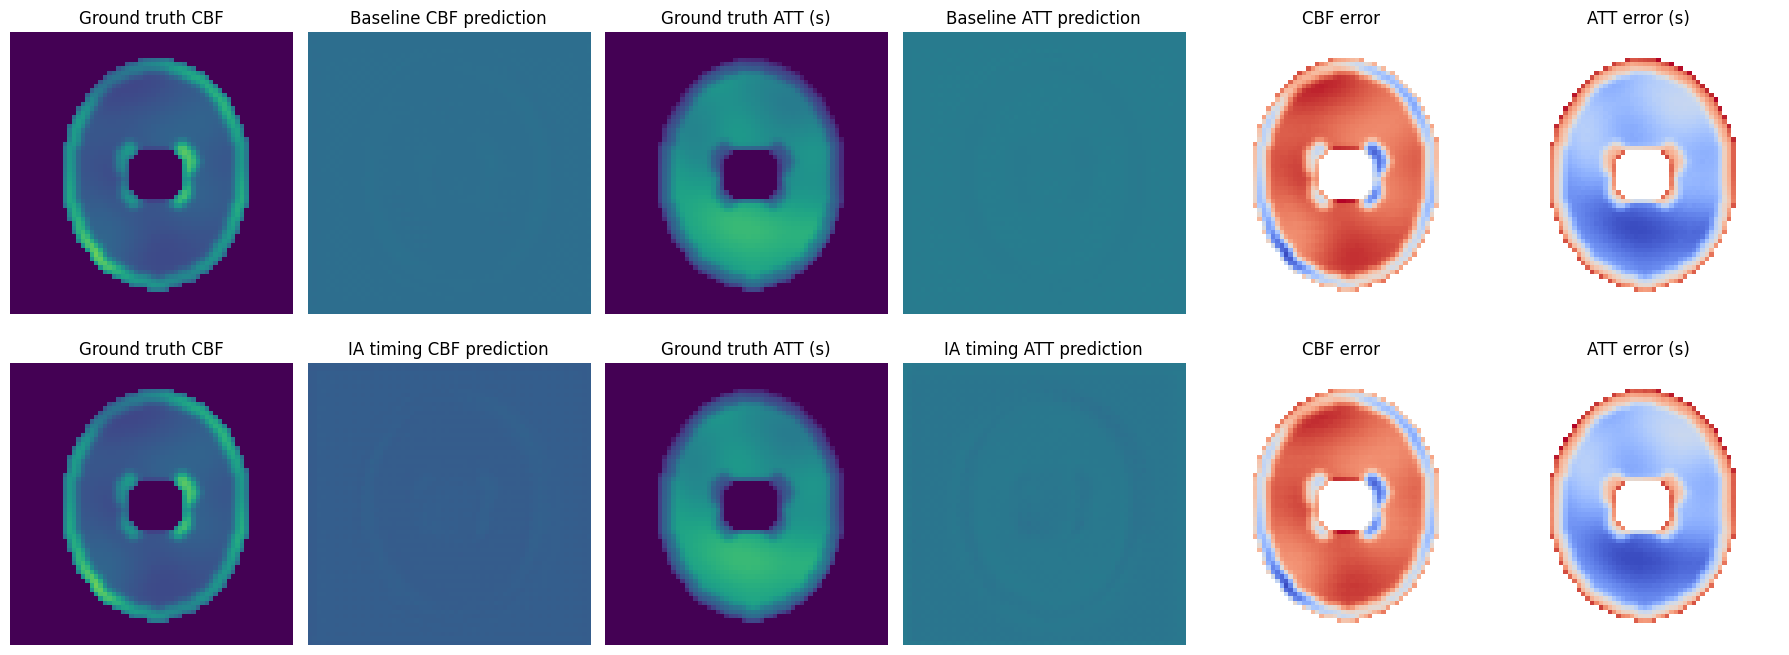

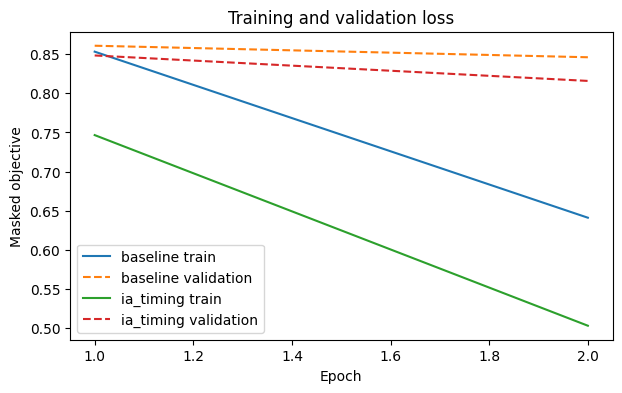

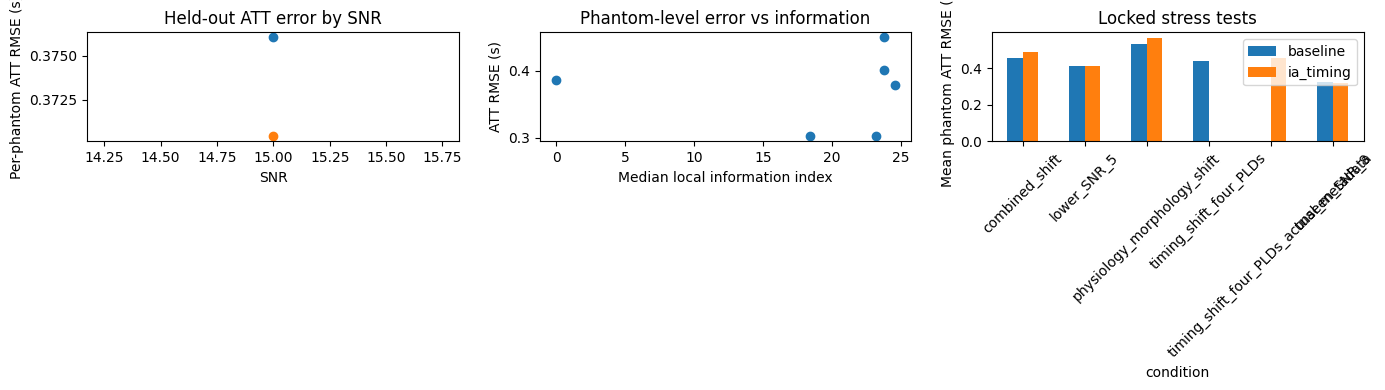

In [13]:
idx=0
m=test["mask"][idx,0]>0.5
prediction_fig,ax=plt.subplots(2,6,figsize=(18,7))
for r,(name,pred) in enumerate([("Baseline",baseline_pred),("IA timing",ia_pred)]):
    ax[r,0].imshow(test["y"][idx,0],vmin=0,vmax=100); ax[r,0].set_title("Ground truth CBF")
    ax[r,1].imshow(pred[idx,0],vmin=0,vmax=100); ax[r,1].set_title(name+" CBF prediction")
    ax[r,2].imshow(test["y"][idx,1],vmin=.5,vmax=3); ax[r,2].set_title("Ground truth ATT (s)")
    ax[r,3].imshow(pred[idx,1],vmin=.5,vmax=3); ax[r,3].set_title(name+" ATT prediction")
    ax[r,4].imshow(np.where(m,pred[idx,0]-test["y"][idx,0],np.nan),cmap="coolwarm"); ax[r,4].set_title("CBF error")
    ax[r,5].imshow(np.where(m,pred[idx,1]-test["y"][idx,1],np.nan),cmap="coolwarm"); ax[r,5].set_title("ATT error (s)")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

history_fig=plt.figure(figsize=(7,4))
for key,result in training_results.items():
    h=result["history"]
    plt.plot(h.epoch,h.train_total_loss,label=key+" train")
    plt.plot(h.epoch,h.val_total_loss,"--",label=key+" validation")
plt.xlabel("Epoch"); plt.ylabel("Masked objective"); plt.title("Training and validation loss")
plt.legend(); plt.show()

summary_fig,ax=plt.subplots(1,3,figsize=(14,4))
for model_name,g in metrics.groupby("model"):
    by=g.groupby("snr").att_rmse.mean()
    ax[0].plot(by.index,by.values,"o-",label=model_name)
ax[0].set(xlabel="SNR",ylabel="Per-phantom ATT RMSE (s)",title="Held-out ATT error by SNR")
if len(ia_ph):
    ax[1].scatter(ia_ph.median_info,ia_ph.att_rmse)
    ax[1].set(xlabel="Median local information index",ylabel="ATT RMSE (s)",title="Phantom-level error vs information")
ss=stress_metrics.groupby(["condition","model"]).att_rmse.mean().unstack()
ss.plot(kind="bar",ax=ax[2]); ax[2].set(ylabel="Mean phantom ATT RMSE (s)",title="Locked stress tests")
ax[2].tick_params(axis="x",rotation=45); ax[2].legend()
plt.tight_layout(); plt.show()
prediction_fig.savefig(OUT/"prediction_and_error_maps.png",dpi=160,bbox_inches="tight")
history_fig.savefig(OUT/"training_validation_curves.png",dpi=160,bbox_inches="tight")
summary_fig.savefig(OUT/"snr_identifiability_stress_summary.png",dpi=160,bbox_inches="tight")

## 14. Automated verification

These assertions fail loudly for critical shape, finite-value, masking, normalization, checkpoint, or evaluation-parity errors. They verify the executed smoke/full run, not general clinical validity. Locked stress test results are not used for model selection or early stopping.

In [14]:
# Reproducibility of a phantom with the same seed and configuration.
_a=generate_phantom(901,"repro",10.0)
_b=generate_phantom(901,"repro",10.0)
np.testing.assert_array_equal(_a["x"],_b["x"])
np.testing.assert_array_equal(_a["y"],_b["y"])
assert _a["metadata"]["sample_id"] == _b["metadata"]["sample_id"]

# Masked loss ignores arbitrarily large background errors.
_pred=torch.zeros(1,2,4,4); _target=torch.ones_like(_pred); _mask=torch.zeros(1,1,4,4)
_mask[:,:,1:3,1:3]=1
_loss=masked_channel_loss(_pred,_target,_mask)
_pred[:,:,0,0]=1e6
_loss_bg=masked_channel_loss(_pred,_target,_mask)
torch.testing.assert_close(_loss,_loss_bg)

# Target normalization round trip and training/test phantom independence.
_round=norm["y_mean"][None,:,None,None]+test["yn"]*norm["y_std"][None,:,None,None]
_valid=np.broadcast_to(test["mask"]>0.5,test["y"].shape)
np.testing.assert_allclose(_round[_valid],test["y"][_valid],rtol=1e-5,atol=1e-5)
assert set(train["ids"]).isdisjoint(set(val["ids"]+test["ids"]))
assert set([r["metadata"]["sample_id"] for r in test_data])==set(test["ids"])
for result in training_results.values():
    assert Path(result["checkpoint"]).exists()
    assert result["history"].shape[0] >= 1
assert baseline_pred.shape==ia_pred.shape==test["y"].shape
assert metrics["sample_id"].nunique()==len(test["ids"])
assert "locked test only" in set(stress_metrics["training_status"])
assert PHYSICS_WEIGHT >= 0
CHECKS.update({
    "phantom_reproducibility":True, "masked_loss":True, "split_independence":True,
    "train_only_normalization_roundtrip":True, "checkpoint_reload":True,
    "matched_test_ids":True, "locked_stress_not_used_for_selection":True,
})
print("CHECK RESULTS")
for name,passed in CHECKS.items(): print(f"{'PASS' if passed else 'FAIL'}: {name}")
assert all(CHECKS.values()), "A critical verification failed; interpret downstream results as invalid."

CHECK RESULTS
PASS: forward_numpy_torch
PASS: zero_noise_factor_2
PASS: noise_variance
PASS: phantom_reproducibility
PASS: masked_loss
PASS: split_independence
PASS: train_only_normalization_roundtrip
PASS: checkpoint_reload
PASS: matched_test_ids
PASS: locked_stress_not_used_for_selection


## 15. Save experiment outputs and generate a report

This final cell writes configuration, dataset metadata, histories, per-phantom and aggregate metrics, timing/identifiability analysis, plots, model checkpoints, and a Markdown report under the configured local output directory. The report is generated from this run's actual tables. Smoke results are labeled preliminary.

In [15]:
config_out=dict(CONFIG)
config_out["active_settings"]=ACTIVE
config_out["runtime"]={"device":str(DEVICE),"cuda":torch.cuda.is_available(),
                       "gpu":gpu_name,"gpu_memory_GiB":gpu_mem_gib}
config_out["reference_audit"]={
    "source":"AnuThmsn/DNN-based-ASL-parameter-estimation-, experiments_unet_4pld",
    "signal_scale":100000.0,"sum_of_two_rician_magnitudes":True,
    "noise_sd_max":66.84078,"baseline_architecture":"double conv U-Net, transposed-conv decoder",
    "optimizer":"AdamW lr=0.001 weight_decay=1e-4; masked L1; ReduceLROnPlateau; grad clip 1.0",
    "smoke_mode_is_not_reference_reproduction":CONFIG["mode"]=="smoke",
}
with open(OUT/"config.json","w",encoding="utf-8") as f: json.dump(config_out,f,indent=2)
dataset_metadata={
    "train_ids":train["ids"],"validation_ids":val["ids"],"test_ids":test["ids"],
    "train_snr":train["snr"].tolist(),"validation_snr":val["snr"].tolist(),"test_snr":test["snr"].tolist(),
    "normalization":{"x_mean":norm["x_mean"],"x_std":norm["x_std"],
                     "y_mean":norm["y_mean"].tolist(),"y_std":norm["y_std"].tolist()},
    "independent_unit":"whole synthetic phantom",
}
with open(OUT/"dataset_metadata.json","w",encoding="utf-8") as f: json.dump(dataset_metadata,f,indent=2)
metrics.to_csv(OUT/"per_phantom_metrics.csv",index=False)
stratified_metrics.to_csv(OUT/"stratified_per_phantom_metrics.csv",index=False)
stratified_summary.to_csv(OUT/"stratified_metric_summary.csv",index=False)
summary.to_csv(OUT/"aggregate_model_comparison.csv")
timing_information.to_csv(OUT/"identifiability_timing_analysis.csv",index=False)
info_df.to_csv(OUT/"test_phantom_identifiability.csv",index=False)
for name,result in training_results.items():
    result["history"].to_csv(OUT/f"{name}_history.csv",index=False)
paired_comparison.to_csv(OUT/"paired_phantom_bootstrap_ci.csv",index=False)
training_summary=pd.DataFrame([{
    "model":name,"training_seconds":result["seconds"],"best_epoch":result["best_epoch"],
    "parameter_count":result["parameters"],"peak_gpu_memory_bytes":result["peak_gpu_memory_bytes"],
    "checkpoint":result["checkpoint"]} for name,result in training_results.items()])
training_summary.to_csv(OUT/"training_summary.csv",index=False)

comparison=metrics.groupby("model")[[
    "att_rmse","att_mae","att_bias","att_pearson_r","att_ccc",
    "cbf_rmse","cbf_mae","cbf_bias","cbf_pearson_r","cbf_ccc",
    "inference_seconds_per_phantom","parameter_count"]].mean()
if {"baseline","ia_timing"}.issubset(comparison.index):
    delta=float(comparison.loc["ia_timing","att_rmse"]-comparison.loc["baseline","att_rmse"])
    interpretation=("IA timing model had lower mean ATT RMSE on this run." if delta<0
                    else "IA timing model did not have lower mean ATT RMSE on this run.")
else:
    delta=float("nan"); interpretation="Insufficient model results for a matched comparison."
if len(paired_comparison):
    ci=paired_comparison.iloc[0]
    if ci["bootstrap_95pct_low"] <= 0 <= ci["bootstrap_95pct_high"]:
        performance_evidence="The paired phantom bootstrap interval includes zero; this run does not establish an ATT improvement."
    elif ci["bootstrap_95pct_high"] < 0:
        performance_evidence="The paired phantom bootstrap interval is below zero for IA minus baseline ATT RMSE; this is run-specific evidence, not a generalization claim."
    else:
        performance_evidence="The paired phantom bootstrap interval is above zero; IA timing did not improve ATT RMSE in this run."
else:
    performance_evidence="No paired interval was available."
worst_case=metrics.loc[metrics["att_rmse"].idxmax()]
run_status=(
    "PRELIMINARY SMOKE TEST" if CONFIG["mode"]=="smoke" else
    ("EXPLORATORY OPTIMIZED TRAINING RUN" if CONFIG["mode"]=="optimized" else
     ("FULL CONFIGURATION, THREE SEEDS" if CONFIG["run_three_seeds"] else "FULL CONFIGURATION, ONE SEED"))
)
ablation_text=ablation_summary.to_string() if len(ablation_metrics) else "Ablations were not enabled for this run; no ablation result is claimed."
report=f'''# ASL identifiability-aware experiment report

**Run status:** {run_status}.

## Question and simulator
Tests whether local information in multi-PLD ASL signals predicts ATT estimation errors and whether timing-conditioned spatial estimation changes errors. The forward equation and SCALE=100000 follow the reference implementation. The observation is a sum of two Rician magnitudes. High-SNR signal consistency uses the explicitly approximate `2 * noiseless_signal`; it is not an exact likelihood.

## Data and models
Independent synthetic brain phantoms were generated at 64x64. Training/validation/test phantom IDs are disjoint. Normalization was fitted on valid training voxels only. Baseline is the reference-style four-channel spatial U-Net with widths {ACTIVE['features']}; IA-ASLNet uses shared per-PLD features and actual PLD conditioning. Full reference width is [32,64,128,256]. Smoke-width/model and short epochs are not baseline reproduction. Optimized mode trains against masked standardized MSE with CBF weight {CONFIG['optimized_cbf_loss_weight']} and ATT weight 1; smoke/full use the reference-style masked L1.

## Training and evaluation
Device: {DEVICE}; train/validation/test counts: {len(train['ids'])}/{len(val['ids'])}/{len(test['ids'])}. Metrics are computed per phantom inside the valid tissue mask and then aggregated across phantoms. No clipping is used. Locked stress conditions were generated after training and not used for selection.

## Results
{comparison.to_string()}

IA minus baseline mean ATT RMSE (seconds): {delta:.6f}. {interpretation}
Paired phantom bootstrap intervals are saved in `paired_phantom_bootstrap_ci.csv`; this resamples whole phantoms, not pixels.
{performance_evidence}
The highest per-phantom ATT RMSE occurred for `{worst_case['sample_id']}` under `{worst_case['model']}`: {worst_case['att_rmse']:.4f} s.

## Ablations
{ablation_text}

## Identifiability
The local information analysis scales CBF and ATT by their full configured ranges and uses a high-SNR Gaussian variance approximation (`2 sigma^2`) to the sum-of-Rician noise. Error association is computed at phantom level and is descriptive at smoke sample sizes. See `identifiability_timing_analysis.csv` and `test_phantom_identifiability.csv`.
{identifiability_association_text}

## Stress tests and caveats
See `stress_test_per_phantom.csv`. Synthetic generator assumptions, 2-D morphology, known noise calibration, limited sample size, and no real ASL-MRI validation limit any conclusion. The smoke run is a pipeline check, not a final scientific claim. The next justified experiment is a larger matched multi-seed run and independent real-data validation if results support it.
'''
(OUT/"experiment_report.md").write_text(report,encoding="utf-8")
print("Saved artifacts to",OUT.resolve())
print(sorted(p.name for p in OUT.iterdir()))
print("Report conclusion:",interpretation)

Saved artifacts to D:\ASL PARAMETER\CNN-UNET\notebooks\outputs\ia_aslnet_experiment
['ablation_per_phantom.csv', 'aggregate_model_comparison.csv', 'baseline_history.csv', 'baseline_seed42_best.pt', 'baseline_seed42_history.csv', 'baseline_seed42_latest.pt', 'config.json', 'dataset_metadata.json', 'example_spatial_phantom.png', 'experiment_report.md', 'ia_timing_history.csv', 'ia_timing_seed42_best.pt', 'ia_timing_seed42_history.csv', 'ia_timing_seed42_latest.pt', 'identifiability_parameter_map.png', 'identifiability_timing_analysis.csv', 'paired_phantom_bootstrap_ci.csv', 'per_phantom_metrics.csv', 'prediction_and_error_maps.png', 'snr_identifiability_stress_summary.png', 'stratified_metric_summary.csv', 'stratified_per_phantom_metrics.csv', 'stress_test_per_phantom.csv', 'test_phantom_identifiability.csv', 'training_summary.csv', 'training_validation_curves.png']
Report conclusion: IA timing model had lower mean ATT RMSE on this run.


### Execution guidance and limitations

- For the quick pipeline check, leave `mode="smoke"`. To try longer training with an RMSE-oriented objective, set `mode="optimized"`; it is still an exploratory synthetic experiment and weights CBF loss more strongly. For the reference-width experiment use `mode="full"`.
- For a larger matched benchmark, set `mode="full"`; adjust batch size if GPU memory is insufficient. Reduce it first for CUDA out-of-memory errors. Checkpoints are saved after each validation improvement.
- Set `run_three_seeds=True` to train/evaluate all configured seeds on the same split. The default is a single seed to keep the smoke run short. Do not pool smoke and full results.
- The baseline takes four fixed channels. IA-ASLNet takes variable PLD counts, but its timing generalization is not established beyond the explicit tests. The paired four-channel shifted-timing condition is the matched comparison.
- The optional information gate and physics loss are exploratory. Enable `run_ablation` only after a sufficiently sized diagnostic indicates the information index may add value. No significance test treats pixels as independent observations.
- Outputs and checkpoints are written only beneath `outputs/ia_aslnet_experiment/` in the current project directory. The notebook does not download data or import from the reference repository.